## Alunos:
### Arthur Nunes
### Bruno Felipe de Souza Araujo
### Caio Cesar Corrá Bello

# Prática — Teste 01 – Atividade Valendo 40% da Média do Bimestre





## Questão 01 (1.0)
a) Considere o dataset abaixo em que cada linha representa uma transação. Explique qual é a unidade de análise e identifique a variável-alvo.

b) Crie o DataFrame e separe X e y, removendo as colunas que não devem ser utilizadas como variáveis explicativas no modelo.


    'transacao_id': [1,2,3,4,5,6,7,8],
    'cliente_id':   [1,1,2,2,3,3,4,4],
    'valor_compra': [100,200,50,80,300,150,400,500],
    'tempo_cliente':[12,12,6,6,24,24,36,36],
    'valor_estornado': [0,200,0,0,300,0,0,500],
    'fraude':       [0,1,0,0,1,0,0,1]


### RESPOSTA

**Item (1A)**  
A unidade de análise adotada neste caso é a transação (cada linha do dataset representa um evento único de compra de um cliente). A variável-alvo é a coluna fraude, que indica o evento que queremos prever (0 para transação legítima, 1 para transação fraudulenta).

In [1]:
# RESPOSTA Item (1B)
# Seu código abaixo:

import subprocess
import sys
import importlib

packages = {
    "pandas": "pandas",
}

for module, package in packages.items():
    try:
        importlib.import_module(module)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

import pandas as pd

dados = {
    'transacao_id': [1,2,3,4,5,6,7,8],
    'cliente_id':   [1,1,2,2,3,3,4,4],
    'valor_compra': [100,200,50,80,300,150,400,500],
    'tempo_cliente':[12,12,6,6,24,24,36,36],
    'valor_estornado': [0,200,0,0,300,0,0,500],
    'fraude':       [0,1,0,0,1,0,0,1]
}
df = pd.DataFrame(dados)

# Removendo identificadores (transacao_id, cliente_id)
# Informações futuras no momento da análise que que geram vazamento (valor_estornado)
# Variavel algo (fraude)
X = df.drop(columns=['transacao_id', 'cliente_id', 'valor_estornado', 'fraude'])
y = df['fraude']

print("Features (X):")
display(X)
print("Variável-alvo (y):")
display(y)

Features (X):


,valor_compra,tempo_cliente
0,100,12
1,200,12
2,50,6
3,80,6
4,300,24
5,150,24
6,400,36
7,500,36


Variável-alvo (y):


,fraude
0,0
1,1
2,0
3,0
4,1
5,0
6,0
7,1


## Questão 02 (1.0)

a) Considere novamente o dataset abaixo. Se o problema for reformulado para o nível de cliente, explique como muda a unidade de análise, a variável-alvo e as variáveis explicativas.

b) Crie o DataFrame abaixo e, em seguida, agregue os dados por cliente_id, de forma que cada linha represente um cliente.
Construa um novo DataFrame com:

soma de valor_compra

quantidade de transações

manter tempo_cliente utilizando o primeiro valor por cliente

variável-alvo: indicar se o cliente teve ao menos uma fraude (valor 1 se sim, 0 caso contrário)

Não utilize a coluna valor_estornado na construção das variáveis explicativas.

Depois, separe X e y.

    'transacao_id': [1,2,3,4,5,6,7,8],
    'cliente_id':   [1,1,2,2,3,3,4,4],
    'valor_compra': [100,200,50,80,300,150,400,500],
    'tempo_cliente':[12,12,6,6,24,24,36,36],
    'valor_estornado': [0,200,0,0,300,0,0,500],
    'fraude':       [0,1,0,0,1,0,0,1]


### RESPOSTA

**Item (2A)**  
Se o problema for reformulado, a unidade de análise passa a ser o cliente (cada linha passa a representar todo o histórico do cliente de forma consolidada). A variável-alvo não será mais a fraude por transação, mas sim se o cliente teve ao menos uma fraude em seu histórico. Já as variáveis explicativas deixam de ser dados pontuais para se tornarem agregações matemáticas (como o total de gastos, média de gastos, contagem de transações, etc.) do comportamento desse cliente.

In [2]:
# RESPOSTA Item (2B)
# Seu código abaixo:

import pandas as pd

dados = {
    'transacao_id': [1,2,3,4,5,6,7,8],
    'cliente_id':   [1,1,2,2,3,3,4,4],
    'valor_compra': [100,200,50,80,300,150,400,500],
    'tempo_cliente':[12,12,6,6,24,24,36,36],
    'valor_estornado': [0,200,0,0,300,0,0,500],
    'fraude':       [0,1,0,0,1,0,0,1]
}
df = pd.DataFrame(dados)

# Agregação por nível de cliente
df_cliente = df.groupby('cliente_id').agg(
    soma_valor_compra=('valor_compra', 'sum'),
    quantidade_transacoes=('transacao_id', 'count'),
    tempo_cliente=('tempo_cliente', 'first'),
    fraude=('fraude', 'max') # Se teve qualquer fraude retornará 1
).reset_index()

# Separando X e y e cliente_id
X = df_cliente.drop(columns=['cliente_id', 'fraude'])
y = df_cliente['fraude']

print("Features Nível Cliente (X):")
display(X)
print("Alvo Nível Cliente (y):")
display(y)

Features Nível Cliente (X):


,soma_valor_compra,quantidade_transacoes,tempo_cliente
0,300,2,12
1,130,2,6
2,450,2,24
3,900,2,36


Alvo Nível Cliente (y):


,fraude
0,1
1,0
2,1
3,1


## Questão 03 (1.0)

a) O que é construção de atributos em análise preditiva?

b) No dataset abaixo, crie uma nova variável chamada valor_medio_por_compra dividindo o total gasto pela quantidade de compras.

    'cliente_id': [1,2,3,4],
    'total_gasto': [1000, 2000, 1500, 3000],
    'qtd_compras': [5, 10, 3, 6]


### RESPOSTA

**Item (3A)**  
A construção de atributos (Feature Engineering) é o processo de utilizar o conhecimento de negócio e a lógica para derivar novas variáveis (features) a partir das originais presentes na base de dados.  
O objetivo principal é capturar relações, padrões ou estruturas que não estão explícitos nos dados originais, melhorando significativamente o poder preditivo do modelo. Em dados tabulares, esta construção de atributos busca produzir novas colunas com maior poder explicativo.

In [3]:
# RESPOSTA Item (3B)
# Seu código abaixo:

import pandas as pd

dados = {
    'cliente_id': [1,2,3,4],
    'total_gasto': [1000, 2000, 1500, 3000],
    'qtd_compras': [5, 10, 3, 6]
}
df = pd.DataFrame(dados)
df['valor_medio_por_compra'] = df['total_gasto'] / df['qtd_compras']

df

,cliente_id,total_gasto,qtd_compras,valor_medio_por_compra
0,1,1000,5,200.0
1,2,2000,10,200.0
2,3,1500,3,500.0
3,4,3000,6,500.0


## Questão 04 (1.0)

a) O que é codificação de variáveis categóricas e por que ela é necessária em modelos preditivos?

b) No dataset abaixo, aplique codificação One-Hot na variável tipo_pagamento.

    'cliente_id': [1,2,3,4],
    'tipo_pagamento': ['cartao', 'boleto', 'pix', 'cartao']


### RESPOSTA

**Item (4A)**  
A codificação de variáveis categóricas é o processo de transformar dados qualitativos (textos ou categorias) em uma representação numérica. Isso é estritamente necessário porque a grande maioria dos algoritmos estatísticos e de aprendizado de máquina realiza cálculos matemáticos e, por isso, só consegue compreender e processar números, sendo incapaz de interpretar strings diretamente.

In [4]:
# RESPOSTA Item (4B)
# Seu código abaixo:

import pandas as pd

dados = {
    'cliente_id': [1,2,3,4],
    'tipo_pagamento': ['cartao', 'boleto', 'pix', 'cartao']
}
df = pd.DataFrame(dados)
df = pd.get_dummies(df, columns=['tipo_pagamento'], dtype=int)

df

,cliente_id,tipo_pagamento_boleto,tipo_pagamento_cartao,tipo_pagamento_pix
0,1,0,1,0
1,2,1,0,0
2,3,0,0,1
3,4,0,1,0


## Questão 05 (1.0)

a) O que é codificação ordinal e em que tipo de variável ela deve ser aplicada?

b) No dataset abaixo, aplique codificação ordinal na variável nivel_cliente, considerando a ordem: baixo < medio < alto.

    'cliente_id': [1,2,3,4],
    'nivel_cliente': ['baixo', 'alto', 'medio', 'baixo']

### RESPOSTA

**Item (5A)**  
A codificação ordinal é a técnica de mapear as categorias em valores numéricos inteiros preservando a ordem ou gradação da categoria original (ex: 1, 2, 3...). Ela deve ser aplicada exclusivamente em variáveis categóricas ordinais, ou seja, em campos que possuam uma hierarquia lógica e uma noção de progresso em suas características (exemplo: porte pequeno/médio/grande, faixas de atraso, ou classes sociais).

In [5]:
# RESPOSTA Item (5B)
# Seu código abaixo:

import pandas as pd

dados = {
    'cliente_id': [1,2,3,4],
    'nivel_cliente': ['baixo', 'alto', 'medio', 'baixo']
}
df = pd.DataFrame(dados)

df['nivel_cliente_codificado'] = df['nivel_cliente'].map({
    'baixo': 1,
    'medio': 2,
    'alto': 3
})

df

,cliente_id,nivel_cliente,nivel_cliente_codificado
0,1,baixo,1
1,2,alto,3
2,3,medio,2
3,4,baixo,1


## Questão 06 (1.0)

a) O que é normalização e qual seu objetivo no contexto de modelos preditivos?

b) No dataset abaixo, aplique normalização (Min-Max) na variável renda, transformando os valores para o intervalo [0,1].

    'cliente_id': [1,2,3,4],
    'renda': [2000, 5000, 3000, 4000]


### RESPOSTA

Item (6A)  
A normalização é uma técnica de escalonamento usada para colocar as variáveis numéricas dentro de um mesmo intervalo predefinido (geralmente de 0 a 1). Seu objetivo no contexto de modelos preditivos é padronizar a magnitude das variáveis para que features com valores absolutos maiores não dominem indevidamente os pesos do modelo (como na regressão) e também para facilitar e acelerar a convergência em algoritmos baseados em cálculo de distâncias.

In [6]:
# RESPOSTA Item (6B)
# Seu código abaixo:

import pandas as pd

dados = {
    'cliente_id': [1,2,3,4],
    'renda': [2000, 5000, 3000, 4000]
}
df = pd.DataFrame(dados)

# Normalização Min-Max ((x - min) / (max - min))
df['renda_normalizada'] = (df['renda'] - df['renda'].min()) / (df['renda'].max() - df['renda'].min())

df

,cliente_id,renda,renda_normalizada
0,1,2000,0.000000
1,2,5000,1.000000
2,3,3000,0.333333
3,4,4000,0.666667


## Questão 07 (1.0)

a) O que é padronização e qual a diferença em relação à normalização?

b) No dataset abaixo, aplique padronização (Z-score) na variável renda.

    'cliente_id': [1,2,3,4],
    'renda': [2000, 5000, 3000, 4000]

### RESPOSTA

**Item (7A)**  
A padronização (também chamada de Z-score) transforma os valores de
uma variável para que passem a ter média 0 e desvio padrão 1. Cada
valor passa a representar quantos desvios-padrão ele está acima ou
abaixo da média da variável.
Esse procedimento é útil quando os algoritmos dependem da escala das
variáveis, pois coloca todas em uma escala comparável baseada na
distribuição dos dados

In [7]:
# RESPOSTA Item (7B)
# Seu código abaixo:

import subprocess
import sys
import importlib

packages = {
    "pandas": "pandas",
    "sklearn": "scikit-learn"
}

for module, package in packages.items():
    try:
        importlib.import_module(module)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

import pandas as pd
from sklearn.preprocessing import StandardScaler

dados = {
    'cliente_id': [1,2,3,4],
    'renda': [2000, 5000, 3000, 4000]
}
df = pd.DataFrame(dados)

scaler = StandardScaler()
df['renda_padronizada'] = scaler.fit_transform(df[['renda']])

df

,cliente_id,renda,renda_padronizada
0,1,2000,-1.341641
1,2,5000,1.341641
2,3,3000,-0.447214
3,4,4000,0.447214


## Questão 08 (1.0)

a) O que é seleção de atributos e qual seu objetivo em análise preditiva?

b) No dataset abaixo, identifique e remova as variáveis que não devem ser utilizadas no modelo e, em seguida, separe X e y.

    'cliente_id': [1,2,3,4],
    'idade': [25, 40, 35, 50],
    'renda_mensal': [2000, 5000, 3000, 4000],
    'renda_anual': [24000, 60000, 36000, 48000],
    'inadimplente': [0,1,0,1]

### RESPOSTA

**Item (8A)**  
A seleção de atributos é o processo de avaliar, pontuar e manter apenas as variáveis mais relevantes para usar na modelagem. O objetivo principal é remover ruídos, redundâncias e multicolinearidades da base, o que diminui o risco de sobreajuste (overfitting), reduz a complexidade e o tempo de treinamento do modelo, além de torná-lo mais interpretável.

In [8]:
# RESPOSTA Item (8B)
# Seu código abaixo:

import pandas as pd

dados = {
    'cliente_id': [1,2,3,4],
    'idade': [25, 40, 35, 50],
    'renda_mensal': [2000, 5000, 3000, 4000],
    'renda_anual': [24000, 60000, 36000, 48000],
    'inadimplente': [0,1,0,1]
}
df = pd.DataFrame(dados)

# A coluna cliente_id é descartada por ser um identificador que não serve para previsão
# A coluna renda_anual é descartada por ser totalmente colinear com renda_mensal (renda_mensal * 12)
# A coluna inadimplente é a variável alvo

X = df.drop(columns=['cliente_id', 'renda_anual', 'inadimplente'])
y = df['inadimplente']

print("Features selecionadas (X):")
display(X)
print("Variável-alvo (y):")
display(y)

Features selecionadas (X):


,idade,renda_mensal
0,25,2000
1,40,5000
2,35,3000
3,50,4000


Variável-alvo (y):


,inadimplente
0,0
1,1
2,0
3,1


## Questão 09 (1.0)

a) Como a correlação pode ser utilizada no processo de seleção de atributos?

b) Crie o DataFrame abaixo, calcule a matriz de correlação e, com base nela, identifique qual variável pode ser removida por redundância. Em seguida, remova essa variável, separe X e y e exiba o resultado.

    "idade": [22, 25, 28, 35, 45, 52, 30, 40],
    "renda": [2500, 3200, 4100, 5200, 7000, 8200, 4500, 6100],
    "anos_estudo": [12, 14, 16, 18, 16, 14, 15, 17],
    "tempo_empresa": [1, 2, 3, 6, 10, 15, 4, 8],
    "salario": [3000, 3500, 4500, 6000, 7200, 8000, 5000, 6500]

### RESPOSTA

**Item (9A)**  
Através da análise da matriz de correlação, podemos avaliar a relação linear das variáveis explicativas entre si. No processo de seleção de atributos, se duas features possuem uma correlação altíssima (próxima de 1 ou -1), significa que elas carregam, estatisticamente, informações muito redundantes (problema de multicolinearidade). Neste caso, podemos descartar uma delas sem impacto negativo, simplificando o modelo.

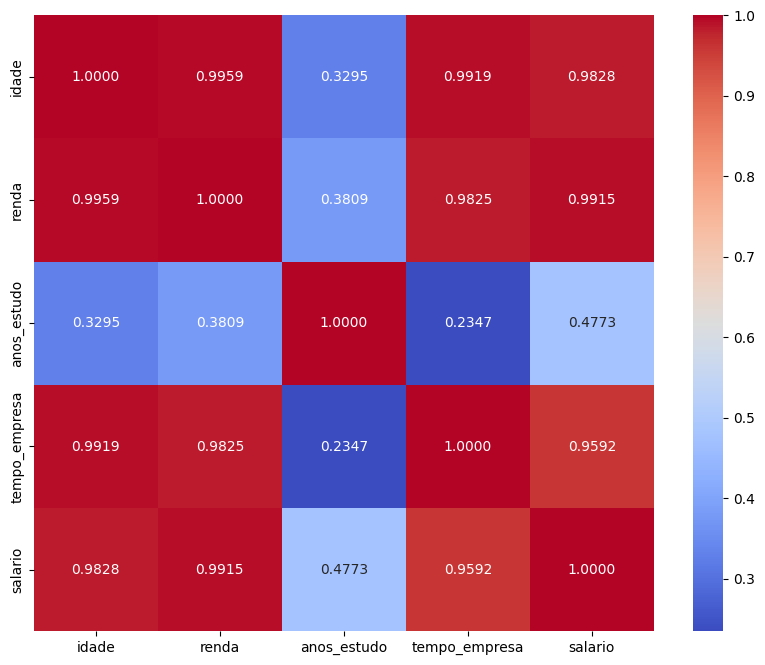

Variável 'renda' descartada por vazamento de dados com o alvo.
Variável 'idade' descartada devido à alta colinearidade com 'tempo_empresa'.

Features (X):


,anos_estudo,tempo_empresa
0,12,1
1,14,2
2,16,3
3,18,6
4,16,10
5,14,15
6,15,4
7,17,8



Alvo (y):


,salario
0,3000
1,3500
2,4500
3,6000
4,7200
5,8000
6,5000
7,6500


In [9]:
# RESPOSTA Item (9B)
# Seu código abaixo:

import subprocess
import sys
import importlib

packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "seaborn": "seaborn",
    "matplotlib": "matplotlib",
}

for module, package in packages.items():
    try:
        importlib.import_module(module)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

dados = {
    "idade": [22, 25, 28, 35, 45, 52, 30, 40],
    "renda": [2500, 3200, 4100, 5200, 7000, 8200, 4500, 6100],
    "anos_estudo": [12, 14, 16, 18, 16, 14, 15, 17],
    "tempo_empresa": [1, 2, 3, 6, 10, 15, 4, 8],
    "salario": [3000, 3500, 4500, 6000, 7200, 8000, 5000, 6500]
}
df = pd.DataFrame(dados)

df.corr(numeric_only=True)

# Visualizar correlações
plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".4f",
    cmap="coolwarm"
)

plt.show()

# Observa-se que "renda" age como um proxy (data leakage) para o "salario", então a descartamos.
# Observa-se também no Heatmap que "idade" e "tempo_empresa" são altamente correlacionadas entre si.
# Para evitar redundância (multicolinearidade), vamos remover a "idade" e manter apenas "tempo_empresa".

X = df.drop(columns=['salario', 'renda', 'idade'])
y = df['salario']

print("Variável 'renda' descartada por vazamento de dados com o alvo.")
print("Variável 'idade' descartada devido à alta colinearidade com 'tempo_empresa'.")
print("\nFeatures (X):")
display(X)
print("\nAlvo (y):")
display(y)


## Questão 10 (1.0)

a) O que é informação mútua e como ela pode ser utilizada na seleção de atributos?

b) Crie o DataFrame abaixo, calcule a informação mútua entre as variáveis explicativas e a variável-alvo e identifique qual variável apresenta menor relevância. Em seguida, remova essa variável, separe X e y e exiba o resultado.

    "temperatura": [15,18,21,24,27,30,33,36,39],
    "marketing": [100,120,140,160,180,200,220,240,260],
    "renda_regiao": [2000,2100,2200,2300,2400,2500,2600,2700,2800],
    "vendas_sorvete": [180,250,330,420,520,630,750,880,1020]

### RESPOSTA

**Item (10A)**  
A informação mútua é uma métrica que captura e avalia as dependências entre duas variáveis, medindo o quanto a inclusão de uma variável reduz a incerteza (entropia) ao tentar prever a variável-alvo. É extremamente útil para seleção de atributos, pois pontuações baixas indicam features que não oferecem aprendizado algum sobre a resposta, devendo ser as primeiras opções a serem removidas da base (e com a vantagem de capturar interações não-lineares também).

In [10]:
# RESPOSTA Item (10B)
# Seu código abaixo:

import pandas as pd
from sklearn.feature_selection import mutual_info_regression

dados = {
    "temperatura": [15,18,21,24,27,30,33,36,39],
    "marketing": [100,120,140,160,180,200,220,240,260],
    "renda_regiao": [2000,2100,2200,2300,2400,2500,2600,2700,2800],
    "vendas_sorvete": [180,250,330,420,520,630,750,880,1020] # Variavel alvo
}
df = pd.DataFrame(dados)

X_temp = df.drop(columns=['vendas_sorvete'])
y = df['vendas_sorvete']

# Computar Scores de Informação Mútua
mi_scores = mutual_info_regression(X_temp, y, random_state=42)
mi_series = pd.Series(mi_scores, index=X_temp.columns).sort_values(ascending=False)

print("Scores de Informação Mútua:")
display(mi_series)

# Removendo a variável com menor relevância baseada na informação mútua
variavel_a_remover = mi_series.idxmin()
print(f"Variável de menor relevância a ser descartada: '{variavel_a_remover}'\n")

X = X_temp.drop(columns=[variavel_a_remover])

print("Features (X) atualizadas:")
display(X)
print("Alvo (y):")
display(y)

Scores de Informação Mútua:


,0
temperatura,0.801190
marketing,0.801190
renda_regiao,0.764153


Variável de menor relevância a ser descartada: 'renda_regiao'

Features (X) atualizadas:


,temperatura,marketing
0,15,100
1,18,120
2,21,140
3,24,160
4,27,180
5,30,200
6,33,220
7,36,240
8,39,260


Alvo (y):


,vendas_sorvete
0,180
1,250
2,330
3,420
4,520
5,630
6,750
7,880
8,1020
